# Template Matching für den Chirp-Mass-Proxy (ET-HF-IMBH)

Zwei Stufen: (1) dichte Template-Bank auf der GPU findet die Region, (2) `LocalRefiner` optimiert kontinuierlich mit direktem LAL-Aufruf (~1 ms pro Wellenform statt ~200 ms über den Dingo-Wrapper), parallel über Injektionen. Die Extrinsik wird **nicht** aus der Injektion übernommen (blind). Die Logik steht in `chirp_mass_matcher.py`.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"
import time
import numpy as np, matplotlib.pyplot as plt, torch
from dingo.core.posterior_models.build_model import build_model_from_kwargs
from dingo.gw.injection import Injection
from dingo.gw.noise.asd_dataset import ASDDataset
import chirp_mass_matcher as cmm

MODEL_NAME = "stage1"   # anpassen
MODEL_PATH = f"/scratch/tpausch/models/{MODEL_NAME}/model_latest.pt"
BANK_PATH  = f"/scratch/tpausch/test_data/{MODEL_NAME}/chirp_mass_bank_lal_v2.pt"
INJECTION_DIR = f"/scratch/tpausch/test_data/{MODEL_NAME}/injections"
N_WORKERS = 32

pm = build_model_from_kwargs(filename=MODEL_PATH, device="cpu", load_training_info=False)
pm_metadata = pm.metadata
generator = Injection.from_posterior_model_metadata(pm.metadata)
del pm

# ASD fuer den Sanity-Check (signal() liefert keinen ASD); Pfad wie in train_settings stage_0
ASD_PATH = "/scratch/tpausch/ASD/asds_ET_T8.hdf5"
asd_dataset = ASDDataset(file_name=ASD_PATH)
generator.asd = {k: v[0] for k, v in asd_dataset.asds.items()}

/home/tpausch/ET-Dingo/dingo/gw/__init__.py:3: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal

WARNING!

This object was created using Dingo version 0.1.dev1230+gc9da5d765 < 0.9.0, which broke backwards compatibility.
For models trained prior to this change, new inference results will be unreliable.
Previously-generated result files should be used with caution.
Reasons for backward compatibility breaking:

v0.9.0: Change to window factor usage, see https://git.li

Putting posterior model to device cpu.
Setting spin_conversion_phase = 0.0. Using this value for the phase parameter for conversion to cartesian spins.
Loading dataset from /scratch/tpausch/ASD/asds_ET_T8.hdf5.


## 1. Bank (einmalig bauen, danach laden)
Mc geometrisch (2 %), q ∈ 12 Werte, χ₁ = χ₂ ∈ 7 Werte, θ_jn ∈ {0.6, π/2}, Phase ∈ 4 Werte. Gebaut wird mit `LALWaveform` statt `make_dingo_h0`: dieselbe Wellenform (siehe Check unten), aber ~200× schneller.

In [2]:
cfg = cmm.BankConfig.from_metadata(
    pm_metadata, dlog_mc=0.02,
    mass_ratios=tuple(np.linspace(0.125, 1, 12)), spin_mode="equal",
    spins=tuple(np.linspace(-0.9, 0.9, 7)),
    phases=tuple(np.linspace(0, 2 * np.pi, 4, endpoint=False)))
print(cfg)
lalwf = cmm.LALWaveform.from_generator(generator, cfg)
print(lalwf.name, "f_ref =", lalwf.f_ref)

if os.path.exists(BANK_PATH):
    bank = cmm.TemplateBank.load(BANK_PATH, device="cuda")
else:
    t0 = time.time()
    h, grid = cmm.build_bank(cfg, lalwf, n_workers=N_WORKERS)
    bank = cmm.TemplateBank(h, grid, cfg, device="cuda")
    bank.save(BANK_PATH)
    del h
    print(f"Bank gebaut in {time.time() - t0:.0f} s")
print(f"{len(bank):,} Templates, {bank.n_mc} Mc-Gitterpunkte")
matcher = cmm.ChirpMassMatcher(bank, oversample=4, t_window=0.125, chunk=256)
refiner = cmm.LocalRefiner(matcher, lalwf)   # Defaults: 2 Starts, 3 Restarts, theta_jn + Phase frei

BankConfig(f_min=6.0, f_max=256.0, delta_f=0.125, mc_min=50.0, mc_max=1000.0, m1_range=(30.0, 3000.0), m2_range=(30.0, 3000.0), d_l_ref=1000.0, dlog_mc=0.02, mc_step=None, mass_ratios=(0.125, 0.20454545454545453, 0.28409090909090906, 0.36363636363636365, 0.4431818181818182, 0.5227272727272727, 0.6022727272727273, 0.6818181818181818, 0.7613636363636364, 0.8409090909090909, 0.9204545454545454, 1.0), spins=(-0.9, -0.6000000000000001, -0.30000000000000004, -1.1102230246251565e-16, 0.29999999999999993, 0.6, 0.9), spin_mode='equal', theta_jn=(0.6, 1.5708), phases=(0.0, 1.5707963267948966, 3.141592653589793, 4.71238898038469))
IMRPhenomXPHM f_ref = 20.0
99,232 Templates, 150 Mc-Gitterpunkte


## 2. Checks
(a) Direkter LAL-Aufruf == Dingo-Wellenform (match und roh > 0.9999). Nur nötig, wenn sich Modell/Approximant ändert.
(b) Rauschfreie Injektionen: Bank-Stufe vs. Refinement, mit Zeitmessung.

In [3]:
asd0 = next(iter(generator.asd.values()))
_ = cmm.check_lal_vs_dingo(generator, cfg, lalwf, n=5, asd=asd0)

Mc=  337.0 q=0.36 theta_jn=0.89  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000
Mc=  307.8 q=0.76 theta_jn=0.89  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000
Generation with parameters (4.095319933924267e+33, 6.322657082762183e+32, 0.0, 0.0, 0.41337980357389925, 0.0, 0.0, -0.5838198829153938, 3.0856775814913673e+25, 0.7577884157395937, 3.402101183476623, 0.0, 0.0, 0.0, 0.125, 6.0, 256.0, 20.0, None, 101) likely numerically unstable due to multibanding, turn off multibanding.
Mc=  652.3 q=0.15 theta_jn=0.76  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000
Mc=  122.7 q=0.49 theta_jn=1.22  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000
Mc=  315.9 q=0.46 theta_jn=1.19  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000


In [4]:
np.random.seed(0)
for _ in range(5):
    theta = {k: float(v) for k, v in generator.prior.sample().items()}
    data = generator.signal(theta)["waveform"]
    t0 = time.time(); est = matcher.estimate(data, generator.asd); t_bank = time.time() - t0
    loc = refiner.refine(data, generator.asd, est)
    print(f"Mc_true={theta['chirp_mass']:6.1f}  bank={est['mc_refined']:6.1f} ({t_bank:.2f} s)  "
          f"local={loc['mc_local']:6.1f} ({loc['t_refine']:.1f} s, {loc['n_wf_calls']} Wellenformen)  "
          f"SNR={loc['snr_local']:.1f}")

Generation with parameters (1.6459352640726175e+33, 6.266670875564885e+32, 0.0, 0.0, 0.20961381148944425, 0.0, 0.0, -0.2809094335418363, 3.085677581491367e+24, 0.9727689295602968, 0.9919762020380174, 0.0, 0.0, 0.0, 0.125, 6.0, 256.0, 20.0, None, 101) likely numerically unstable due to multibanding, turn off multibanding.
Mc_true= 434.8  bank= 304.8 (0.69 s)  local= 434.4 (2.9 s, 2390 Wellenformen)  SNR=120.9
Generation with parameters (2.0441357854480704e+33, 1.6994630752360963e+33, 0.0, 0.0, -0.19237288731853033, 0.0, 0.0, -0.7467025736666844, 3.085677581491367e+24, 1.3762360442765007, 3.9609151597127354, 0.0, 0.0, 0.0, 0.125, 6.0, 256.0, 20.0, None, 101) likely numerically unstable due to multibanding, turn off multibanding.
Mc_true= 815.3  bank= 828.7 (0.51 s)  local= 833.1 (1.3 s, 1623 Wellenformen)  SNR=1091.3
Mc_true= 154.4  bank= 155.8 (0.51 s)  local= 153.3 (1.9 s, 1036 Wellenformen)  SNR=55.9
Mc_true=  97.2  bank=  99.5 (0.51 s)  local=  96.9 (5.3 s, 2210 Wellenformen)  SNR=85

## 3. Injektionen auswerten
Erst mit wenigen Injektionen die Zeit prüfen, dann `MAX_INJ = None`.

In [5]:
MAX_INJ = 1000
t0 = time.time()
res = cmm.evaluate_injections(matcher, INJECTION_DIR, max_injections=MAX_INJ, kernel_halfwidth=45.0,
                              refiner=refiner, n_workers=N_WORKERS)
print(f"{len(res)} Injektionen in {time.time() - t0:.0f} s "
      f"(Refinement im Mittel {res.t_refine.mean():.1f} s/Injektion pro Worker, "
      f"{res.n_wf_calls.mean():.0f} Wellenformen)")
if MAX_INJ is None:
    res.to_csv(os.path.join(os.path.dirname(INJECTION_DIR), "matched_filter_results.csv"), index=False)
res[[c for c in res if c.startswith("inside_")]].mean()   # Anteil innerhalb Kernel +-45

Bank-Stufe fertig, verfeinere 1000 Injektionen mit 32 Workern ...
1000 Injektionen in 930 s (Refinement im Mittel 13.4 s/Injektion pro Worker, 1922 Wellenformen)


inside_mc_argmax      0.494
inside_mc_refined     0.500
inside_mc_weighted    0.497
inside_mc_median      0.498
inside_mc_mean        0.502
inside_mc_local       0.691
dtype: float64

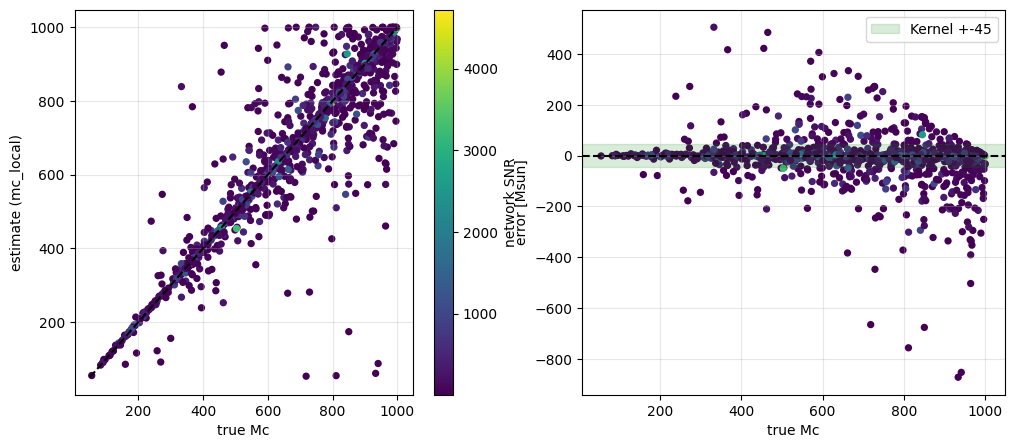

bin
1         [1.0, 1.0, 1.0]
2         [0.9, 3.2, 5.3]
3        [1.2, 7.0, 58.4]
4     [4.6, 102.0, 255.9]
5      [8.2, 73.3, 410.0]
6    [14.3, 125.8, 383.2]
7    [23.6, 180.2, 477.1]
dtype: object
Anteil innerhalb Kernel +-50 Msun: 0.707


In [6]:
EST = "mc_local"   # Refinement-Ergebnis; zum Vergleich "mc_refined" (nur Bank)
err = res[EST] - res.chirp_mass_true
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sc = ax[0].scatter(res.chirp_mass_true, res[EST], c=res.snr_local, s=18, cmap="viridis")
lim = [cfg.mc_min, cfg.mc_max]; ax[0].plot(lim, lim, "k--"); plt.colorbar(sc, ax=ax[0], label="network SNR")
ax[0].set(xlabel="true Mc", ylabel=f"estimate ({EST})")
ax[1].scatter(res.chirp_mass_true, err, s=18, c=res.snr_local)
ax[1].axhspan(-45, 45, color="g", alpha=0.15, label="Kernel +-45")
ax[1].axhline(0, color="k", ls="--"); ax[1].set(xlabel="true Mc", ylabel="error [Msun]"); ax[1].legend()
for a in ax: a.grid(alpha=0.3)
plt.show()

# Fehlerquantile in Mc-Bins -> Grundlage fuer die Kernel-Breite
bins = np.geomspace(cfg.mc_min, cfg.mc_max, 8)
res["bin"] = np.digitize(res.chirp_mass_true, bins)
print(err.abs().groupby(res["bin"]).agg(lambda x: np.quantile(x, [0.5, 0.9, 0.99]).round(1).tolist()))
print("Anteil innerhalb Kernel +-50 Msun:", (err.abs() < 50).mean())

## 4. Diagnose: Optimierer oder Physik?
Vergleicht das gefundene ρ² mit ρ² der **wahren** Parameter (Extrinsik weiterhin maximiert).
- `drho2 >= 0`: der Optimierer hat das Maximum gefunden → der Mc-Fehler ist statistisch (Mc–q-Entartung bei diesem SNR). Besser wird es dann nur mit Marginalisierung/Posterior, nicht mit mehr Optimierung.
- `drho2 << 0`: der Optimierer ist hängen geblieben → `restarts`, `n_starts` oder die Bank verbessern.

In [7]:
from pathlib import Path
rows = []
for fn in sorted(Path(INJECTION_DIR).glob("inj_*.pkl"))[:20]:
    theta, data, asds = cmm.load_injection(fn)
    theta = {k: float(v) for k, v in theta.items() if np.ndim(v) == 0}
    est = matcher.estimate(data, asds)
    job = refiner.prepare(data, asds, est)
    loc = refiner.optimize(job)
    r2_true = cmm._rho2_np(lalwf(theta), job["w"], job["inv_psd"], cfg.i_min, matcher.M, matcher.K)
    rows.append(dict(file=fn.name, mc_true=theta["chirp_mass"], mc_local=loc["mc_local"],
                     err=loc["mc_local"] - theta["chirp_mass"], snr_true=np.sqrt(r2_true),
                     drho2=loc["snr_local"] ** 2 - r2_true, t=loc["t_refine"]))
import pandas as pd
diag = pd.DataFrame(rows)
diag.round(2)

,file,mc_true,mc_local,err,snr_true,drho2,t
0,inj_0000.pkl,911.76,932.28,20.52,158.81,3.82,0.79
1,inj_0001.pkl,649.37,537.97,-111.40,452.41,-25.53,2.70
2,inj_0002.pkl,929.11,956.71,27.60,166.06,-1.10,0.90
3,inj_0003.pkl,434.55,433.78,-0.77,815.75,85.71,1.57
4,inj_0004.pkl,838.12,855.97,17.85,66.11,1.91,2.11
5,inj_0005.pkl,335.88,340.25,4.37,594.27,67.25,1.57
6,inj_0006.pkl,907.10,913.10,6.00,331.78,-24.68,0.95
7,inj_0007.pkl,982.01,997.78,15.77,34.54,2.55,2.01
8,inj_0008.pkl,219.45,227.05,7.60,182.64,-23.01,1.92
9,inj_0009.pkl,313.06,310.03,-3.03,177.65,9.54,3.21


In [8]:
#print mean and median of rho2 difference and error in chirp mass
print("Mean error in chirp mass:", diag.err.mean())
print("Median error in chirp mass:", diag.err.median())
print("Mean difference in rho2:", diag.drho2.mean())
print("Median difference in rho2:", diag.drho2.median())

Mean error in chirp mass: 7.031149019401774
Median error in chirp mass: 4.98119822303309
Mean difference in rho2: -14.224763241637081
Median difference in rho2: 3.180646080623461
